# Central Limit Theorem and the Binomial Distribution

## 1. Binomial as a sum of Bernoulli variables

Let $X \sim \text{Binomial}(n,p)$ and $q = 1-p$. Then

$$
X = X_1 + X_2 + \cdots + X_n, \qquad X_i \overset{\text{iid}}{\sim} \text{Bernoulli}(p),
$$

with

$$
\mathbb{E}[X_i] = p, \qquad \operatorname{Var}(X_i) = pq .
$$

By linearity and independence,

$$
\mathbb{E}[X] = np, \qquad \operatorname{Var}(X) = npq .
$$

The probability mass function is

$$
P(X = i) = \binom{n}{i} p^i q^{\,n-i}, \qquad i = 0,1,\dots,n .
$$

## 2. Standardization

The standardized variable and its values are

$$
Z_n = \frac{X - np}{\sqrt{npq}}, \qquad z_i = \frac{i - np}{\sqrt{npq}} .
$$

This is what `z = (np.arange(n+1) - n*p)/np.sqrt(n*p*q)` computes in the code. Only the **values** of $X$ are standardized. The probabilities $P(X=i)$ are left unchanged.

## 3. The Central Limit Theorem (general case)

Let $X_1, X_2, \dots$ be i.i.d. with finite mean $\mu$ and finite variance $\sigma^2 > 0$. Then

$$
Z_n = \frac{X_1 + \cdots + X_n - n\mu}{\sigma\sqrt{n}} \xrightarrow{\,d\,} \mathcal{N}(0,1),
$$

which means that for every $z \in \mathbb{R}$,

$$
P(Z_n \le z) \longrightarrow \Phi(z) = \int_{-\infty}^{z} \frac{1}{\sqrt{2\pi}}\, e^{-t^2/2}\, dt
\qquad (n \to \infty).
$$

Equivalently, for any $a < b$,

$$
P(a \le Z_n \le b) \longrightarrow \Phi(b) - \Phi(a).
$$

**Binomial case.** Setting $\mu = p$ and $\sigma^2 = pq$ gives the **de Moivre–Laplace theorem**:

$$
\frac{X - np}{\sqrt{npq}} \xrightarrow{\,d\,} \mathcal{N}(0,1).
$$

## 4. Proof sketch (characteristic functions)

Let $Y_i = (X_i - \mu)/\sigma$, so $\mathbb{E}[Y_i]=0$ and $\operatorname{Var}(Y_i)=1$. Then

$$
Z_n = \frac{1}{\sqrt{n}} \sum_{i=1}^{n} Y_i .
$$

1. By independence, the characteristic function of $Z_n$ is
$$
\varphi_{Z_n}(t) = \left[\varphi_Y\!\left(\tfrac{t}{\sqrt{n}}\right)\right]^n .
$$

2. A Taylor expansion at $0$, using $\mathbb{E}[Y]=0$ and $\mathbb{E}[Y^2]=1$, gives
$$
\varphi_Y(s) = 1 - \frac{s^2}{2} + o(s^2).
$$

3. Therefore
$$
\varphi_{Z_n}(t) = \left(1 - \frac{t^2}{2n} + o\!\left(\tfrac{1}{n}\right)\right)^n \longrightarrow e^{-t^2/2}.
$$

4. $e^{-t^2/2}$ is the characteristic function of $\mathcal{N}(0,1)$. By **Lévy's continuity theorem**, $Z_n \xrightarrow{d} \mathcal{N}(0,1)$.

Only the first two moments survive in the limit, which is why the theorem holds for almost any distribution with finite variance.

## 5. What the CLT does and does not say

The CLT is a statement about **CDFs** (probabilities of intervals). It does **not** say that

$$
P(X=i) \approx \varphi(z_i), \qquad \varphi(z) = \tfrac{1}{\sqrt{2\pi}}e^{-z^2/2},
$$

because each $P(X=i) \to 0$ as $n \to \infty$.

## 6. Local limit theorem (pmf vs. density)

Neighboring standardized values are spaced

$$
\Delta z = \frac{1}{\sqrt{npq}}
$$

apart, so the probability mass **per unit of $z$** is

$$
\frac{P(X=i)}{\Delta z} = \sqrt{npq}\; P(X=i).
$$

The **de Moivre–Laplace local limit theorem** states that

$$
\sqrt{npq}\; P(X=i) \;\approx\; \frac{1}{\sqrt{2\pi}}\, e^{-z_i^2/2},
$$

uniformly in $i$ over $|z_i| \le C$.

In the code:

- `k` is $P(X=i)$, which lies below the curve.
- `a = k*np.sqrt(n*p*q)` is $\sqrt{npq}\,P(X=i)$, which follows the curve.

## 7. Practical approximation with continuity correction

Since a discrete variable is approximated by a continuous one,

$$
P(X \le m) \approx \Phi\!\left(\frac{m + \tfrac12 - np}{\sqrt{npq}}\right).
$$

## 8. Speed of convergence

The **Berry–Esseen theorem** bounds the maximum CDF error:

$$
\sup_{z} \left| P(Z_n \le z) - \Phi(z) \right| \le \frac{C\,\rho}{\sigma^3 \sqrt{n}},
\qquad \rho = \mathbb{E}\,|X_1 - \mu|^3 .
$$

The error is of order $1/\sqrt{n}$. For the binomial, the leading asymmetry is governed by the skewness

$$
\gamma = \frac{1 - 2p}{\sqrt{npq}},
$$

so for $p = 0.2$ the distribution is right-skewed, and convergence is slower than for $p = 0.5$. Increasing $n$ makes the points hug the normal curve more closely.

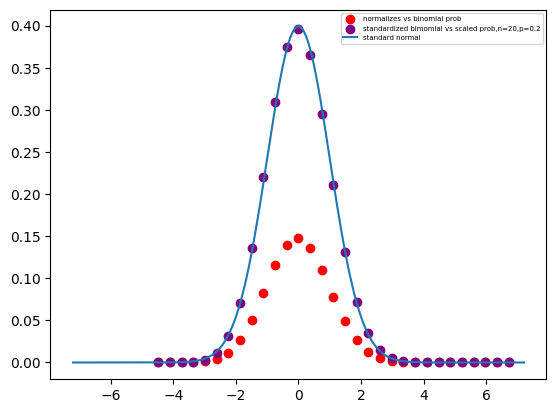

In [22]:
import numpy as np
import matplotlib.pyplot as plt

def fta(x):#this was not needed still i like it :)
 p=np.zeros([len(x)])
 k=0
 for t in x:
    r=1
    for i in range(t):
        r=r*(i+1)
    p[k]=r
    k=k+1
 return p

def ft(x):
   p=1

   for i in range(x):
      p=p*(i+1)
   return p

def f(n,p):
   k=np.zeros(n+1)
   q=1-p
   for i in range(n+1):
      k[i]=ft(n)/(ft(i)*ft(n-i))*p**i*(q)**(n-i)
   return (np.arange(n+1)-n*p)/np.sqrt(n*p*q),k
n,p=30,0.4
q=1-p
z,k=f(n,p)
plt.scatter(z,k,color="red",label="normalizes vs binomial prob") 

a=k*np.sqrt(n*p*q)
plt.scatter(z,a,color="purple",label="standardized bimomial vs scaled prob,n=20,p=0.2")
x=np.linspace(-n*p*q,n*p*q,10000)
y=np.exp(-x**2/2)/np.sqrt(2*np.pi)
plt.plot(x,y,label="standard normal")
plt.legend(loc="upper right", fontsize=5, frameon=True)

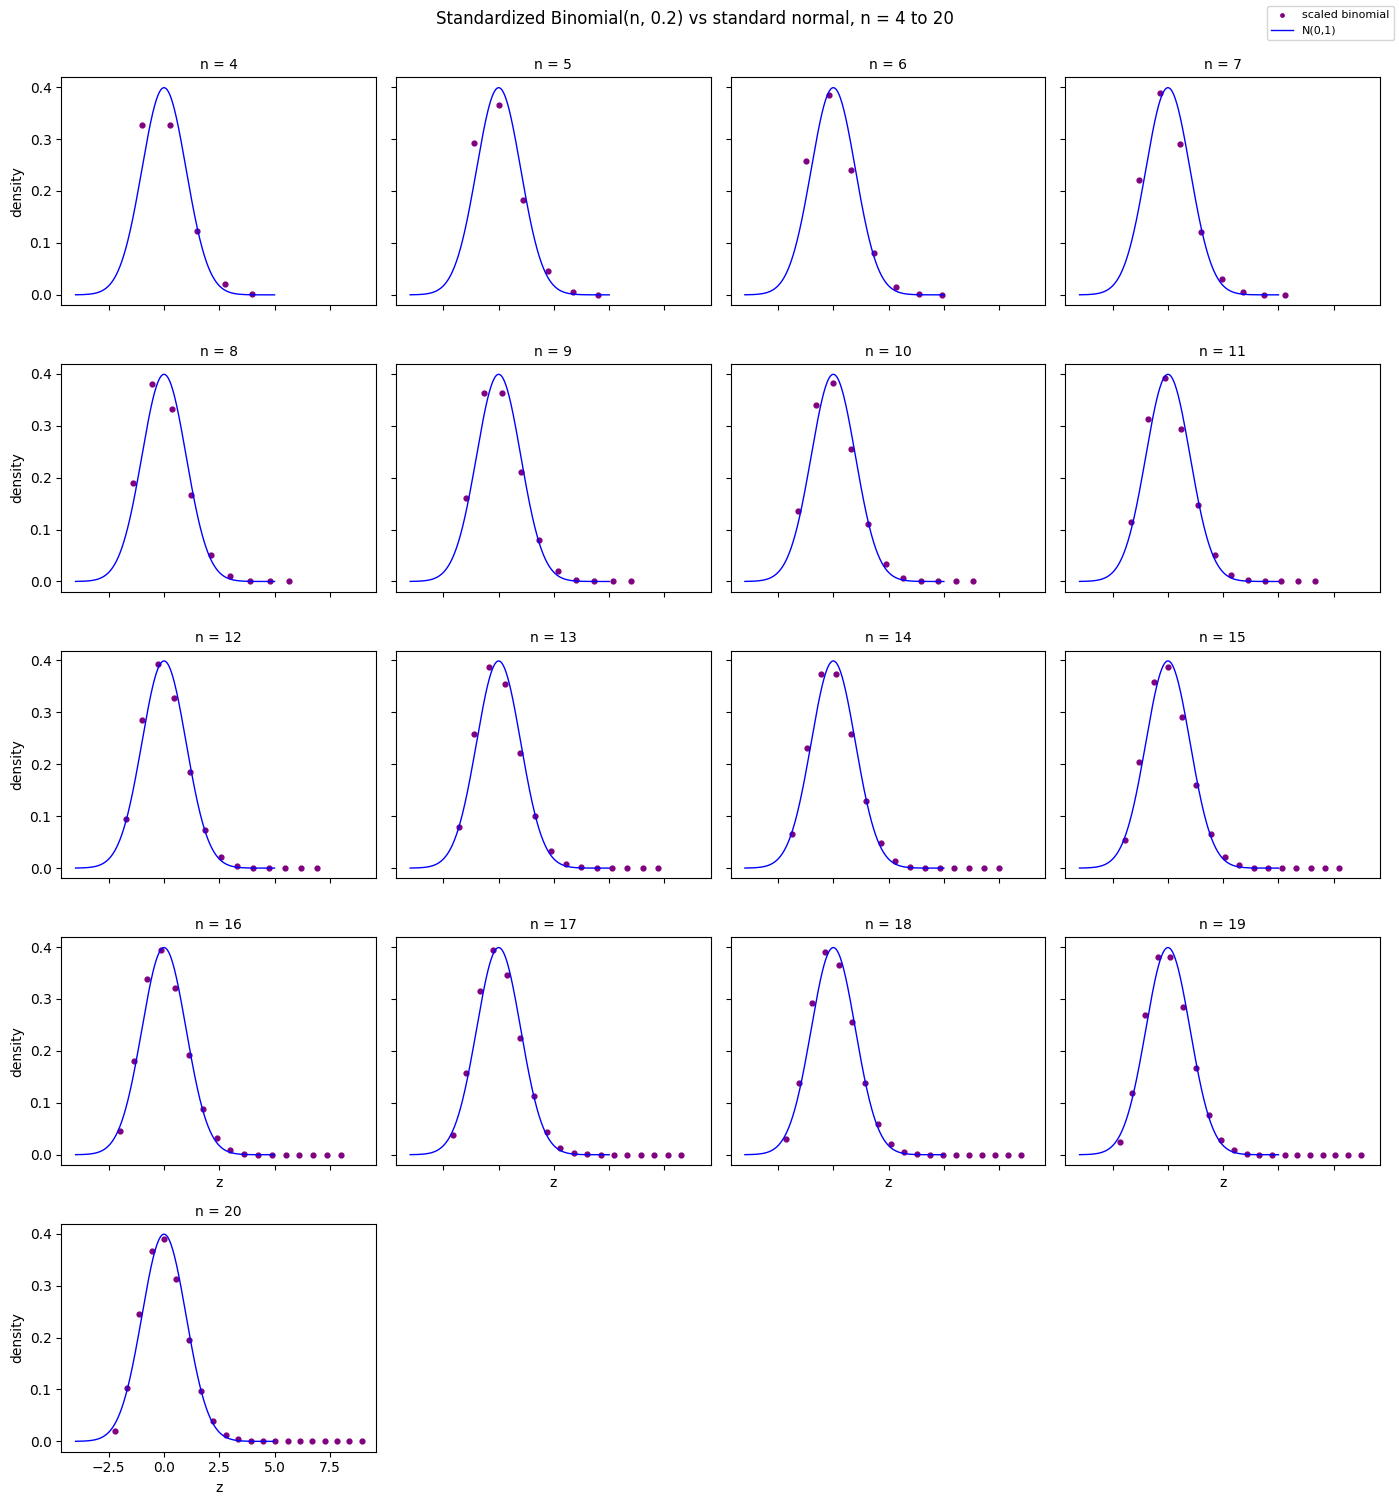

In [ ]:
from math import ceil

p = 0.2
q = 1 - p
ns = range(4, 21)                 

ncols = 4
nrows = ceil(len(ns) / ncols)     

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3*nrows),
                         sharex=True, sharey=True)
axes = axes.flatten()

x = np.linspace(-4, 5, 500)
y = np.exp(-x**2/2) / np.sqrt(2*np.pi)

for ax, n in zip(axes, ns):
    z, k = f(n, p)                       
    a = k * np.sqrt(n*p*q)              
    ax.scatter(z, a, color="purple", s=12, label="scaled binomial")
    ax.plot(x, y, color="blue", lw=1, label="N(0,1)")
    ax.set_title(f"n = {n}", fontsize=10)

# hide unused axes (20 slots, 17 plots)
for ax in axes[len(ns):]:
    ax.set_visible(False)

# axis labels only on the outer edges
for ax in axes[:len(ns)]:
    if ax.get_subplotspec().is_last_row() or ax.get_subplotspec().rowspan.stop == nrows - 1:
        ax.set_xlabel("z")
for r in range(nrows):
    axes[r*ncols].set_ylabel("density")

# one shared legend for the whole figure
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", fontsize=8, markerscale=0.7)

fig.suptitle("Standardized Binomial(n, 0.2) vs standard normal, n = 4 to 20", y=1.0)
plt.tight_layout()
plt.show()

Here we see that we dont need very large n and 20 is good here gives good aproxmation of for aplliction of central limit therom that is what makes to very useful